## Libraries

**Legacy example.** This notebook is the original EMUstack notebook of the same name. The `LEGACY_PARAMS` switch in the next cell selects the inputs:

- `LEGACY_PARAMS = True` *(default)*: the legacy inputs, unchanged (128 wavelengths, about 30 minutes). T, R and A then agree with legacy EMUstack to 4e-6, on the same mesh (checked in `benchmarks/parity/`, `examples/` version, see `PARITY_RESULTS.md`).
- `LEGACY_PARAMS = False`: 16 wavelengths instead of 128.

In [1]:
# True: the inputs of the original EMUstack example, unchanged.
# False: same structure, 16 wavelengths instead of 128.
LEGACY_PARAMS = True

In [2]:
# libraries
import numpy as np
import sys
sys.path.append("../backend/")
%matplotlib inline
import matplotlib.pylab as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

import objects
objects.default_mesher = 'netgen'  # this folder: native netgen meshes (examples/ uses legacy gmsh meshes)
import materials
import plotting
from stack import *

#parallel
import concurrent.futures
%matplotlib inline


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## EMUstack: Au Nanodisk array with interpolators
We show the potential of interpolators with a simple calculation. We calculate the Transmission and Reflection spectra of an **Au Nanodisk Array** with pitch **nd_p=600nm** and disk radius and height  **nd_r=100 nm** and **nd_h=100 nm**. Then we use the interpolators to plot all the field componentes at the system resonance within the notebook.

In [3]:
# light parameters
wl_1 = 300
wl_2 = 800
n_wl = 128 if LEGACY_PARAMS else 16

# Set up light objects
wavelengths = np.linspace(wl_1,wl_2, n_wl)
light_list  = [objects.Light(wl, max_order_PWs = 2,theta=0.0,phi=0.0) for wl in wavelengths]

# nanodisk array r and pitch in nm
nd_r = 100
nd_p = 600
nd_h = 100

# defining the layers: period must be consistent throughout simulation!!!
NHs = objects.NanoStruct(
    '2D_array',
    height_nm=nd_h,
    inclusion_a=materials.Au,
    background=materials.Air,
    loss=True,
    inc_shape='circle',
    plotting_fields=False,
    plot_real=1,
    plt_msh=True,
    geo_params={
        'period': nd_p,
        'diameter1': 2.0 * nd_r,
        'lc': 0.12,
        'lc2': 5.0,
        'lc3': 3.0,
    }
)

superstrate = objects.ThinFilm(period = nd_p, height_nm = 'semi_inf',
    material = materials.Air, loss = False)
substrate   = objects.ThinFilm(period = nd_p, height_nm = 'semi_inf',
    material = materials.Air, loss = False)


In [4]:
# EMUstack Function
def simulate_stack(light):

    # evaluate each layer individually 
    sim_NHs          = NHs.calc_modes(light)
    sim_superstrate  = superstrate.calc_modes(light)
    sim_substrate    = substrate.calc_modes(light)

    # build the stack solution
    stackSub = Stack((sim_substrate, sim_NHs, sim_superstrate))
    stackSub.calc_scat(pol = 'TM')

    return stackSub

In [5]:
%%time
# computation
with concurrent.futures.ThreadPoolExecutor(max_workers=24) as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


no more timer available (lff_from_py), reusing last one


CPU times: user 16min 32s, sys: 20.9 s, total: 16min 53s
Wall time: 2min 19s


# Spectra plot

In [6]:
# spectra
a_list = []
t_list = []
r_list = []
for stack in stacks_list:
    a_list.extend(stack.a_list)
    t_list.extend(stack.t_list)
    r_list.extend(stack.r_list)
layers_steps = len(stacks_list[0].layers) - 1
a_tot      = []
t_tot      = []
r_tot      = []
for i in range(len(wavelengths)):
    a_tot.append(float(a_list[layers_steps-1+(i*layers_steps)]))
    t_tot.append(float(t_list[layers_steps-1+(i*layers_steps)]))
    r_tot.append(float(r_list[i]))

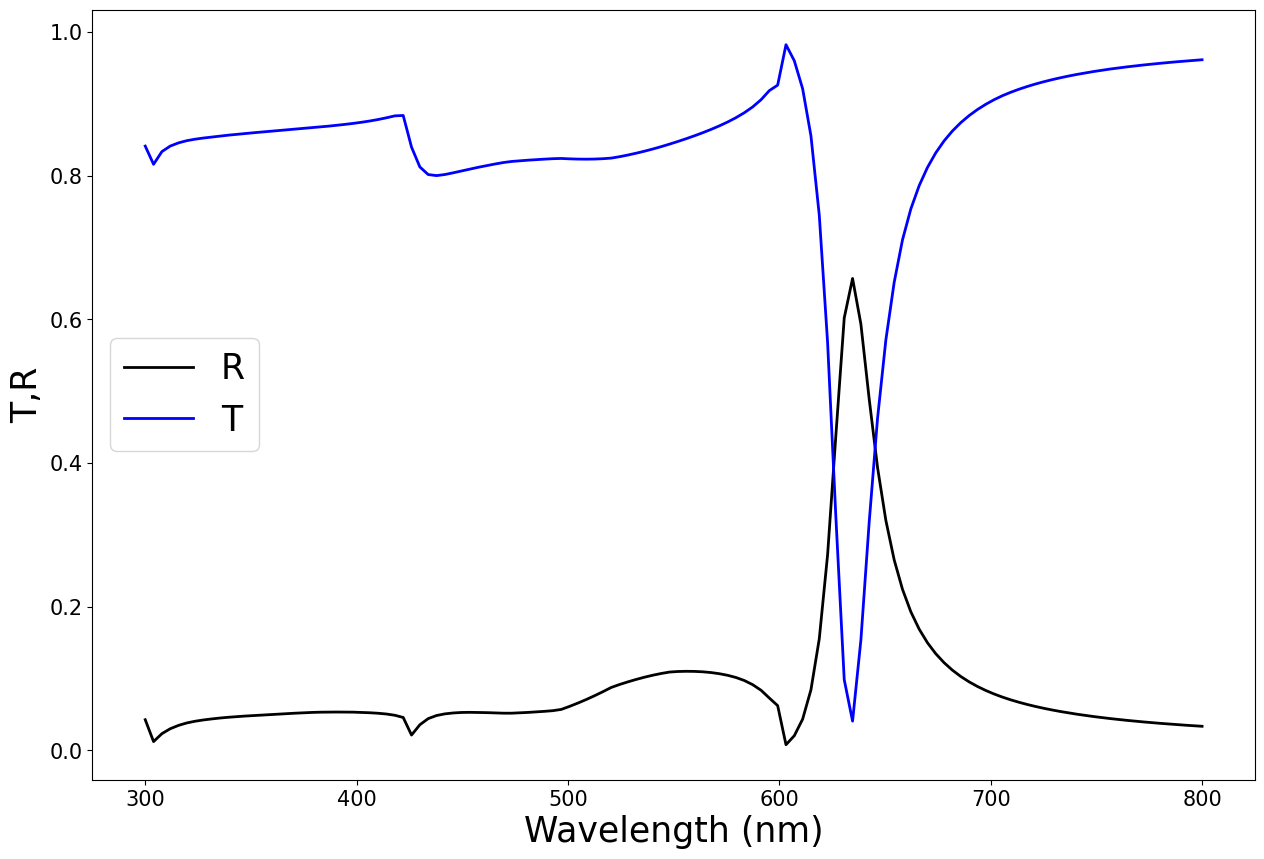

In [7]:
# T and R spectra
plt.figure(figsize=(15,10))
plt.plot(wavelengths,np.array(r_tot),'k',
         wavelengths,np.array(t_tot),'b',linewidth = 2.0);
f_size=25;

# labels
plt.xlabel("Wavelength (nm)",fontsize = f_size);
plt.ylabel("T,R",fontsize = f_size);

# ticks
plt.xticks(fontsize=f_size-10);
plt.yticks(fontsize=f_size-10);

# legend
plt.legend( ["R","T"],fontsize = f_size, loc='center left',fancybox=True);

# Triangulation field plot

In [8]:
# defining the layers: period must be consistent throughout simulation!!!
NHs = objects.NanoStruct(
    '2D_array',
    height_nm=nd_h,
    inclusion_a=materials.Au,
    background=materials.Air,
    loss=True,
    inc_shape='circle',
    plotting_fields=True,
    plot_real=1,
    plt_msh=True,
    geo_params={
        'period': nd_p,
        'diameter1': 2.0 * nd_r,
        'lc': 0.12,
        'lc2': 5.0,
        'lc3': 3.0,
    }
)
stack = simulate_stack(light_list[np.array(r_tot).argmax()])


In [9]:
# triangular interpolation computation
ReEx,ImEx,ReEy,ImEy,ReEz,ImEz,AbsE = plotting.fields_interpolator_in_plane(stack,lay_interest=1,z_value=0.1)

# field mapping
n_points=150
v_x=np.zeros(n_points**2)
v_y=np.zeros(n_points**2)
i=0
x_min=0.0;x_max=1.0
y_min=0.0;y_max=1.0
for x in np.linspace(x_min,x_max,n_points):
    for y in np.linspace(y_min,y_max,n_points):
        v_x[i] = x
        v_y[i] = y
        i+=1
v_x = np.array(v_x)
v_y = np.array(v_y)

# interpolated fields
m_ReEx = ReEx(v_x,v_y).reshape(n_points,n_points)
m_ReEy = ReEy(v_x,v_y).reshape(n_points,n_points)
m_ReEz = ReEz(v_x,v_y).reshape(n_points,n_points)
m_ImEx = ImEx(v_x,v_y).reshape(n_points,n_points)
m_ImEy = ImEy(v_x,v_y).reshape(n_points,n_points)
m_ImEz = ImEz(v_x,v_y).reshape(n_points,n_points)
m_AbsE = AbsE(v_x,v_y).reshape(n_points,n_points)
v_plots = [m_ReEx,m_ReEy,m_ReEz,m_ImEx,m_ImEy,m_ImEz,m_AbsE]
v_labels = ["ReEx","ReEy","ReEz","ImEx","ImEy","ImEz","AbsE"]


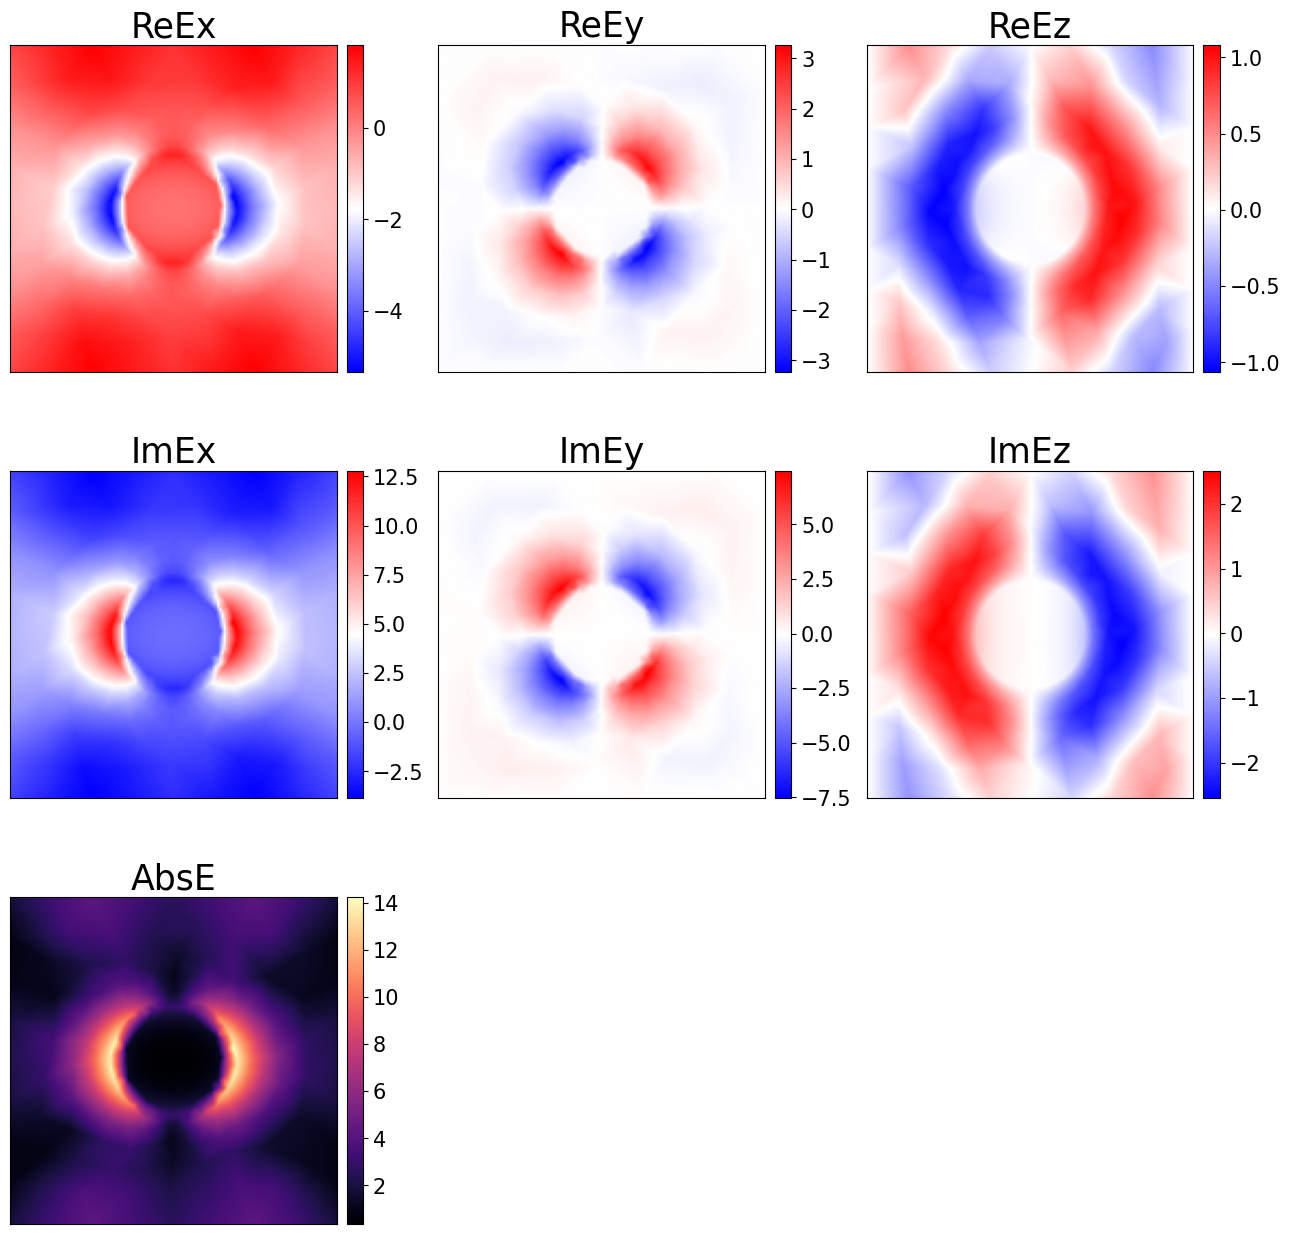

In [10]:
# field plots
plt.figure(figsize=(13,13))
colormap = 'bwr'
for i_p,plot in enumerate(v_plots):
    ax = plt.subplot(3,3,i_p+1)
    if i_p == 6:
        colormap='magma'
    im = plt.imshow(plot.T,cmap=colormap);
    
    # no ticks
    plt.xticks([])
    plt.yticks([])
    
    # titles
    plt.title(v_labels[i_p],fontsize=f_size)
    
    # colorbar
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = plt.colorbar(im, cax=cax)
    cbar.ax.tick_params(labelsize=f_size-10) 
plt.tight_layout()